# Etap 2 — Reprodukcja: Grounding DINO-T, zero-shot na COCO val2017

**Eksperyment 01 (`exp01_coco_zeroshot_val2017`)** — najprostszy wynik z artykułu do odtworzenia.

| | |
|---|---|
| Artykuł | Liu et al., *Grounding DINO*, arXiv:2303.05499, **Tabela 2** |
| Model | Grounding DINO T (Swin-T), pretrening O365 + GoldG + Cap4M = checkpoint `groundingdino_swint_ogc.pth` |
| Wagi u nas | `IDEA-Research/grounding-dino-tiny` (Hugging Face) — oficjalna konwersja `groundingdino_swint_ogc.pth` do `transformers` (bez kompilacji CUDA ops, patrz ryzyko *Techniczne 2* w karcie) |
| Zbiór | MS COCO 2017 **val** (5000 obrazów, 80 klas), model **nie widział COCO** w treningu → zero-shot |
| Wynik autorów | **AP = 48.4** (COCO mAP@[.50:.95]) |

### Protokół ewaluacji (taki jak w oficjalnym `demo/test_ap_on_coco.py`)
1. Jeden prompt ze wszystkimi 80 nazwami klas: `"person . bicycle . car . ... . toothbrush ."`.
2. Model zwraca 900 zapytań × 256 tokenów (sigmoid = prawdopodobieństwo tokenu).
3. **Positive map**: każda klasa ↦ jej tokeny w prompcie; wynik klasy = średnia prawdopodobieństw jej tokenów.
4. Top-300 par (zapytanie, klasa) na obraz — **bez progów** (progi zaniżyłyby AP).
5. `pycocotools.COCOeval` → AP, AP50, AP75, APs/m/l, AR.

Dodatkowo (sekcja 8) — metryki z karty projektu dla trybu „praktycznego”, z progiem `box_threshold`: Precision, Recall, średnie IoU dopasowań przy IoU@0.5, liczba brakujących (FN) i nadmiarowych (FP) ramek.

### Dane
Pobierane **automatycznie** w sekcji 2 z oficjalnej strony COCO (bez Kaggle):
- `http://images.cocodataset.org/zips/val2017.zip` (~0.8 GB)
- `http://images.cocodataset.org/annotations/annotations_trainval2017.zip` (~0.25 GB)

Lądują w `data/coco/` (ignorowane przez git). Wyniki: `results/exp01_coco_zeroshot_val2017/<run>/`.

## 1. Konfiguracja

In [1]:
import json
import platform
import random
import time
import urllib.request
import zipfile
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from PIL import Image
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm import tqdm
from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor

/home/rafal/Repositories/GroundingDINO_reproduction/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ===================== PARAMETRY EKSPERYMENTU =====================
EXPERIMENT = "exp01_coco_zeroshot_val2017"
MODEL_ID = "IDEA-Research/grounding-dino-tiny"   # = groundingdino_swint_ogc.pth

N_IMAGES = None     # None -> cały val2017 (5000 obrazów, ~16 min na RTX 5070); np. 500 -> szybki test
SEED = 42             # losowanie podzbioru obrazów (gdy N_IMAGES != None)
NUM_SELECT = 300      # top-k detekcji na obraz dla COCO AP (jak w oficjalnym skrypcie)

BOX_THRESHOLD = 0.35  # próg pewności dla metryk "praktycznych"
IOU_MATCH = 0.5       # IoU wymagane do uznania detekcji za trafioną (sekcja 8)

RERUN_INFERENCE = False  # True -> wymuś ponowną inferencję, nawet jeśli predykcje są zapisane

# Wyniki autorów (Tabela 2 artykułu, Grounding DINO T, O365+GoldG+Cap4M, zero-shot COCO val2017)
PAPER_RESULTS = {"AP": 48.4}
# ===================================================================

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"device={DEVICE}", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

device=cuda NVIDIA GeForce RTX 5070


In [3]:
# ===================== ŚCIEŻKI =====================
def find_repo_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    raise RuntimeError("Nie znaleziono katalogu głównego repo (pyproject.toml)")

ROOT = find_repo_root()
COCO_DIR = ROOT / "data" / "coco"
IMG_DIR = COCO_DIR / "val2017"
ANN_FILE = COCO_DIR / "annotations" / "instances_val2017.json"

RUN_NAME = f"swint_ogc_hf__n{N_IMAGES or 'all'}_seed{SEED}"
RUN_DIR = ROOT / "results" / EXPERIMENT / RUN_NAME
FIG_DIR = RUN_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

PRED_FILE = RUN_DIR / "predictions.json"   # surowe detekcje w formacie COCO results (duży plik, w .gitignore)
print("repo:", ROOT)
print("run :", RUN_DIR.relative_to(ROOT))

repo: /home/rafal/Repositories/GroundingDINO_reproduction
run : results/exp01_coco_zeroshot_val2017/swint_ogc_hf__nall_seed42


## 2. Dane — pobranie COCO val2017

Pobiera się tylko raz; przy kolejnych uruchomieniach komórka nic nie robi. Archiwa `.zip` zostają w `data/coco/_downloads/` — po rozpakowaniu można je usunąć.

In [4]:
COCO_URLS = {
    "val2017.zip": "http://images.cocodataset.org/zips/val2017.zip",
    "annotations_trainval2017.zip": "http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
}

def download(url: str, dst: Path) -> Path:
    if dst.exists():
        return dst
    dst.parent.mkdir(parents=True, exist_ok=True)
    tmp = dst.with_suffix(dst.suffix + ".part")
    with urllib.request.urlopen(url) as r, open(tmp, "wb") as f, \
         tqdm(total=int(r.headers.get("Content-Length", 0)), unit="B", unit_scale=True, desc=dst.name) as bar:
        while chunk := r.read(1 << 20):
            f.write(chunk)
            bar.update(len(chunk))
    tmp.rename(dst)
    return dst

def ensure_coco_val2017():
    if IMG_DIR.exists() and ANN_FILE.exists() and len(list(IMG_DIR.glob("*.jpg"))) == 5000:
        print("COCO val2017 już jest:", COCO_DIR.relative_to(ROOT))
        return
    for name, url in COCO_URLS.items():
        zpath = download(url, COCO_DIR / "_downloads" / name)
        print("rozpakowuję", name)
        with zipfile.ZipFile(zpath) as z:
            z.extractall(COCO_DIR)   # -> data/coco/val2017/, data/coco/annotations/

ensure_coco_val2017()

COCO val2017 już jest: data/coco


In [5]:
coco_gt = COCO(str(ANN_FILE))
cat_ids = sorted(coco_gt.getCatIds())                       # 80 id (nieciągłe: 1..90)
cat_names = [coco_gt.cats[c]["name"] for c in cat_ids]

all_img_ids = sorted(coco_gt.getImgIds())
if N_IMAGES is None:
    img_ids = all_img_ids
else:
    img_ids = sorted(random.Random(SEED).sample(all_img_ids, N_IMAGES))
n_gt = len(coco_gt.getAnnIds(imgIds=img_ids, iscrowd=False))
print(f"obrazy: {len(img_ids)} / {len(all_img_ids)}, ramki GT (bez crowd): {n_gt}, klasy: {len(cat_ids)}")

loading annotations into memory...
Done (t=0.19s)
creating index...
index created!
obrazy: 5000 / 5000, ramki GT (bez crowd): 36335, klasy: 80


## 3. Model

In [6]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForZeroShotObjectDetection.from_pretrained(MODEL_ID).to(DEVICE).eval()
MAX_TEXT_LEN = model.config.max_text_len   # 256
print(f"parametry: {sum(p.numel() for p in model.parameters())/1e6:.1f} M, max_text_len={MAX_TEXT_LEN}")

Loading weights: 100%|██████████| 978/978 [00:00<00:00, 1894.86it/s]


parametry: 172.3 M, max_text_len=256


## 4. Prompt i *positive map*

Prompt to nazwy klas COCO połączone `" . "` — tak jak w oficjalnej ewaluacji. Kropki działają jako separatory: model maskuje atencję między frazami (*sub-sentence level*, sekcja 3.4 artykułu).

`positive_map[k, t] = 1/|tokeny klasy k|` dla tokenów `t` należących do nazwy klasy `k` (np. `"traffic light"` → 2 tokeny). Wtedy `prob_klasy = prob_tokenów @ positive_map.T`.

## uzupełnić opisy!

In [7]:
def build_prompt_and_positive_map(names, tokenizer, max_text_len):
    caption, spans = "", []
    for name in names:
        spans.append((len(caption), len(caption) + len(name)))
        caption += name + " . "
    caption = caption.strip()                # "... toothbrush ."
    enc = tokenizer(caption)
    pos = torch.zeros(len(names), max_text_len)
    for k, (beg, end) in enumerate(spans):
        t0, t1 = enc.char_to_token(beg), enc.char_to_token(end - 1)
        pos[k, t0 : t1 + 1] = 1.0
    assert len(enc["input_ids"]) <= max_text_len, "prompt za długi"
    return caption, pos / pos.sum(-1, keepdim=True)

CAPTION, POSITIVE_MAP = build_prompt_and_positive_map(cat_names, processor.tokenizer, MAX_TEXT_LEN)
POSITIVE_MAP = POSITIVE_MAP.to(DEVICE)
print(f"tokenów w prompcie: {len(processor.tokenizer(CAPTION)['input_ids'])}")
print(CAPTION[:120], "...")

tokenów w prompcie: 195
person . bicycle . car . motorcycle . airplane . bus . train . truck . boat . traffic light . fire hydrant . stop sign . ...


## 5. Inferencja

In [8]:
@torch.inference_mode()
def predict_coco(image: Image.Image, image_id: int) -> list[dict]:
    inputs = processor(images=image, text=CAPTION, return_tensors="pt").to(DEVICE)
    out = model(**inputs)

    prob_tok = out.logits[0].sigmoid()                  # (900, 256); tokeny poza tekstem -> 0
    prob_cls = prob_tok @ POSITIVE_MAP.T                # (900, 80)
    scores, flat_idx = prob_cls.flatten().topk(NUM_SELECT)
    q_idx = flat_idx // prob_cls.shape[1]
    c_idx = flat_idx % prob_cls.shape[1]

    W, H = image.size
    cx, cy, w, h = out.pred_boxes[0][q_idx].unbind(-1)  # znormalizowane cxcywh
    boxes = torch.stack([(cx - w / 2) * W, (cy - h / 2) * H, w * W, h * H], -1)  # COCO: xywh w pikselach

    return [
        {"image_id": image_id, "category_id": cat_ids[c], "bbox": [round(v, 2) for v in b], "score": round(s, 5)}
        for c, b, s in zip(c_idx.tolist(), boxes.tolist(), scores.tolist())
    ]


def current_config() -> dict:
    return {
        "experiment": EXPERIMENT, "model_id": MODEL_ID, "n_images": len(img_ids), "seed": SEED,
        "num_select": NUM_SELECT, "caption": CAPTION,
        "image_size": dict(processor.image_processor.size), "dtype": str(next(model.parameters()).dtype),
    }


def run_inference() -> list[dict]:
    preds, times = [], []
    w = Image.open(IMG_DIR / coco_gt.imgs[img_ids[0]]["file_name"]).convert("RGB")
    predict_coco(w, img_ids[0])   # rozgrzewka GPU (pierwsze wywołanie trwa kilka s), nie wliczamy do czasu
    for image_id in tqdm(img_ids, desc="inferencja"):
        info = coco_gt.imgs[image_id]
        image = Image.open(IMG_DIR / info["file_name"]).convert("RGB")
        if DEVICE == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        preds += predict_coco(image, image_id)
        if DEVICE == "cuda": torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    runtime = {"sec_per_image_mean": float(np.mean(times)), "sec_total": float(np.sum(times))}
    return preds, runtime


cfg_file = RUN_DIR / "config.json"
cached = PRED_FILE.exists() and cfg_file.exists() and json.loads(cfg_file.read_text()) == current_config()
if cached and not RERUN_INFERENCE:
    predictions = json.loads(PRED_FILE.read_text())
    print(f"Wczytano {len(predictions)} zapisanych predykcji z {PRED_FILE.relative_to(ROOT)}")
else:
    predictions, runtime = run_inference()
    PRED_FILE.write_text(json.dumps(predictions))
    cfg_file.write_text(json.dumps(current_config(), indent=2, ensure_ascii=False))
    env = {
        "python": platform.python_version(), "torch": torch.__version__, "transformers": transformers.__version__,
        "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
        **runtime,
    }
    (RUN_DIR / "env.json").write_text(json.dumps(env, indent=2))
    print(json.dumps(env, indent=2))

Wczytano 1500000 zapisanych predykcji z results/exp01_coco_zeroshot_val2017/swint_ogc_hf__nall_seed42/predictions.json


## 6. Ewaluacja COCO (AP) — porównywalna z Tabelą 2

In [9]:
coco_dt = coco_gt.loadRes(predictions)
coco_eval = COCOeval(coco_gt, coco_dt, iouType="bbox")
coco_eval.params.imgIds = img_ids          # ewaluacja tylko na wybranym podzbiorze
coco_eval.evaluate(); coco_eval.accumulate(); coco_eval.summarize()

STAT_NAMES = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large",
              "AR_1", "AR_10", "AR_100", "AR_small", "AR_medium", "AR_large"]
coco_metrics = {k: round(float(v) * 100, 2) for k, v in zip(STAT_NAMES, coco_eval.stats)}
(RUN_DIR / "metrics_coco.json").write_text(json.dumps(coco_metrics, indent=2))

Loading and preparing results...
DONE (t=0.84s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=25.92s).
Accumulating evaluation results...
DONE (t=7.66s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.486
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.645
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.531
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.340
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.518
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.634
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.386
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.669
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.739
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

233

In [10]:
comparison = pd.DataFrame(
    [{"metric": k, "paper": PAPER_RESULTS.get(k), "ours": v} for k, v in coco_metrics.items()]
)
comparison["diff (ours - paper)"] = (comparison["ours"] - comparison["paper"]).round(2)
comparison.insert(0, "n_images", len(img_ids))
comparison.to_csv(RUN_DIR / "comparison_with_paper.csv", index=False)
comparison

,n_images,metric,paper,ours,diff (ours - paper)
0,5000,AP,48.4,48.61,0.21
1,5000,AP50,NaN,64.52,NaN
2,5000,AP75,NaN,53.12,NaN
3,5000,AP_small,NaN,34.05,NaN
4,5000,AP_medium,NaN,51.78,NaN
5,5000,AP_large,NaN,63.39,NaN
6,5000,AR_1,NaN,38.59,NaN
7,5000,AR_10,NaN,66.88,NaN
8,5000,AR_100,NaN,73.89,NaN
9,5000,AR_small,NaN,59.41,NaN


**Interpretacja:**
- Artykuł raportuje dla tego wariantu tylko AP (48.4); pozostałe metryki to nasz dodatkowy wynik (brak odniesienia).
- Przy `N_IMAGES < 5000` AP jest tylko estymatą na podzbiorze (na 50 obrazach wyszło np. 55.7 — różnica rzędu kilku pkt). Do porównania z paperem liczy się `N_IMAGES = None`.
- Możliwe źródła różnic przy pełnym zbiorze: konwersja wag do `transformers` (inna implementacja deformable attention niż kompilowane CUDA ops), resize/interpolacja obrazu, precyzja obliczeń, wersje bibliotek.

### AP per klasa

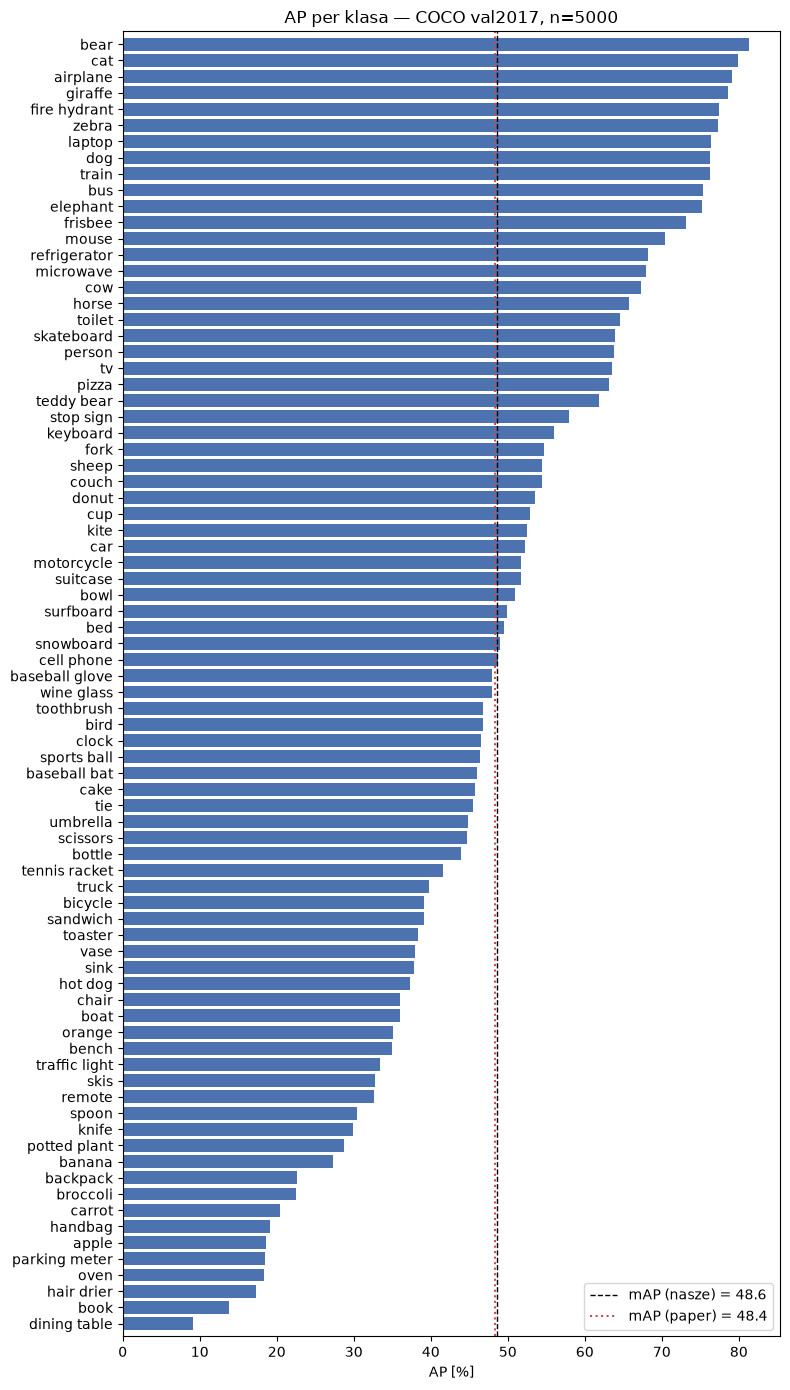

,category,AP,AP50,n_gt
21,bear,81.28,91.36,71
15,cat,79.91,93.22,202
4,airplane,79.06,92.62,143
23,giraffe,78.53,94.08,232
10,fire hydrant,77.36,93.46,101
22,zebra,77.33,92.83,266
63,laptop,76.38,89.45,231
16,dog,76.29,87.30,218
6,train,76.24,91.27,190
5,bus,75.33,87.93,283


,category,AP,AP50,n_gt
24,backpack,22.57,40.53,371
50,broccoli,22.45,37.07,312
51,carrot,20.38,29.98,365
26,handbag,19.17,31.70,540
47,apple,18.65,25.39,236
12,parking meter,18.45,28.01,60
69,oven,18.39,34.18,143
78,hair drier,17.30,33.54,11
73,book,13.85,19.90,1129
60,dining table,9.14,13.95,695


In [11]:
# precision: [T=10 progów IoU, R=101 recall, K=klasy, A=obszary, M=maxDets]; A=0 -> 'all', M=-1 -> 100 detekcji
prec = coco_eval.eval["precision"]

def ap_from(p):
    p = p[p > -1]
    return float(p.mean() * 100) if p.size else float("nan")

per_class = pd.DataFrame({
    "category": cat_names,
    "AP": [ap_from(prec[:, :, k, 0, -1]) for k in range(len(cat_ids))],
    "AP50": [ap_from(prec[0, :, k, 0, -1]) for k in range(len(cat_ids))],
    "n_gt": [len(coco_gt.getAnnIds(imgIds=img_ids, catIds=[c], iscrowd=False)) for c in cat_ids],
}).round(2).sort_values("AP", ascending=False)
per_class.to_csv(RUN_DIR / "metrics_per_class.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 14))
ax.barh(per_class["category"][::-1], per_class["AP"][::-1], color="#4C72B0")
ax.axvline(coco_metrics["AP"], color="k", ls="--", lw=1, label=f"mAP (nasze) = {coco_metrics['AP']:.1f}")
ax.axvline(PAPER_RESULTS["AP"], color="#C44E52", ls=":", lw=1.5, label=f"mAP (paper) = {PAPER_RESULTS['AP']}")
ax.set_xlabel("AP [%]"); ax.set_title(f"AP per klasa — COCO val2017, n={len(img_ids)}")
ax.legend(loc="lower right"); ax.margins(y=0.005)
fig.tight_layout(); fig.savefig(FIG_DIR / "ap_per_class.png", dpi=150); plt.show()

display(per_class.head(10)); display(per_class.dropna().tail(10))

## 7. Krzywa Precision–Recall (IoU = 0.5 i 0.75)

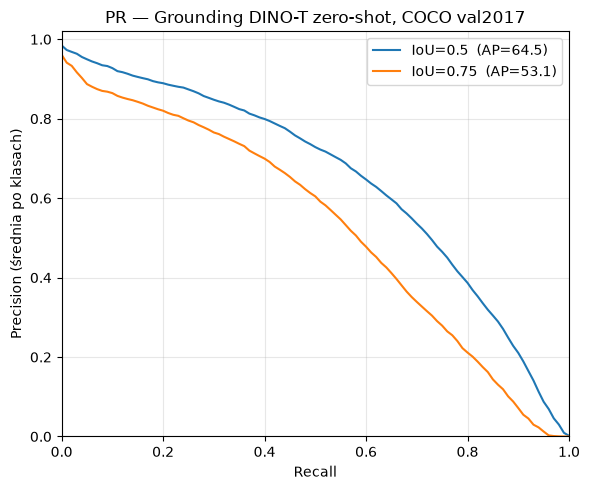

In [12]:
rec_thrs = coco_eval.params.recThrs
fig, ax = plt.subplots(figsize=(6, 5))
for t_idx, iou in [(0, 0.5), (5, 0.75)]:
    p = prec[t_idx, :, :, 0, -1]                       # (101, K)
    p = np.where(p > -1, p, np.nan)
    ax.plot(rec_thrs, np.nanmean(p, axis=1), label=f"IoU={iou}  (AP={ap_from(prec[t_idx, :, :, 0, -1]):.1f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision (średnia po klasach)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend()
ax.set_title("PR — Grounding DINO-T zero-shot, COCO val2017")
fig.tight_layout(); fig.savefig(FIG_DIR / "pr_curve.png", dpi=150); plt.show()

## 8. Metryki z karty projektu: Precision / Recall / IoU@0.5 przy progu `box_threshold`

AP nie wymaga progu, ale w praktyce Grounding DINO używa się z progiem (`box_threshold=0.35` w demo autorów). Tutaj:
- bierzemy te same predykcje, zostawiamy tylko te ze `score ≥ BOX_THRESHOLD`,
- w każdym obrazie, dla każdej klasy, dopasowujemy zachłannie (od najwyższego score) detekcje do GT przy IoU ≥ 0.5,
- **TP** = trafione, **FP** = nadmiarowe ramki, **FN** = brakujące ramki; detekcje na obszarach `iscrowd` są ignorowane.

> `text_threshold` w tym protokole nie występuje — etykieta pochodzi z *positive map* (klasa ↦ jej tokeny), a nie z wyboru tokenów powyżej progu jak w demo. Będzie istotny w Etapie 3 (dowolne frazy).

In [13]:
def threshold_metrics(predictions, score_thr, iou_thr):
    dets = defaultdict(list)
    for d in predictions:
        if d["score"] >= score_thr:
            dets[(d["image_id"], d["category_id"])].append(d)

    stats = {c: {"TP": 0, "FP": 0, "FN": 0, "iou_sum": 0.0} for c in cat_ids}
    for img in img_ids:
        anns = coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img))
        for c in cat_ids:
            gt = np.array([a["bbox"] for a in anns if a["category_id"] == c and not a["iscrowd"]]).reshape(-1, 4)
            crowd = np.array([a["bbox"] for a in anns if a["category_id"] == c and a["iscrowd"]]).reshape(-1, 4)
            ds = sorted(dets.get((img, c), []), key=lambda d: -d["score"])
            s = stats[c]
            if not ds:
                s["FN"] += len(gt); continue
            db = np.array([d["bbox"] for d in ds], dtype=np.float64)
            ious = mask_utils.iou(db, gt, [0] * len(gt)) if len(gt) else np.zeros((len(ds), 0))
            ioa_crowd = mask_utils.iou(db, crowd, [1] * len(crowd)) if len(crowd) else np.zeros((len(ds), 0))
            matched = np.zeros(len(gt), bool)
            for i in range(len(ds)):
                cand = np.where(~matched, ious[i], -1) if len(gt) else np.array([])
                j = int(cand.argmax()) if cand.size else -1
                if j >= 0 and cand[j] >= iou_thr:
                    matched[j] = True; s["TP"] += 1; s["iou_sum"] += float(ious[i, j])
                elif ioa_crowd.shape[1] and ioa_crowd[i].max() >= iou_thr:
                    pass                                   # trafienie w obszar 'crowd' -> ignorujemy
                else:
                    s["FP"] += 1
            s["FN"] += int((~matched).sum())

    df = pd.DataFrame([{"category": coco_gt.cats[c]["name"], **v} for c, v in stats.items()])
    tot = df[["TP", "FP", "FN", "iou_sum"]].sum()
    summary = {
        "box_threshold": score_thr, "iou_match": iou_thr,
        "TP": int(tot.TP), "FP (nadmiarowe)": int(tot.FP), "FN (brakujące)": int(tot.FN),
        "precision": tot.TP / max(tot.TP + tot.FP, 1),
        "recall": tot.TP / max(tot.TP + tot.FN, 1),
        "mean_IoU_of_TP": tot.iou_sum / max(tot.TP, 1),
    }
    df["precision"] = df.TP / (df.TP + df.FP).clip(lower=1)
    df["recall"] = df.TP / (df.TP + df.FN).clip(lower=1)
    df["mean_IoU_of_TP"] = df.iou_sum / df.TP.clip(lower=1)
    return summary, df.drop(columns="iou_sum")


thr_summary, thr_per_class = threshold_metrics(predictions, BOX_THRESHOLD, IOU_MATCH)
thr_per_class.round(3).to_csv(RUN_DIR / "metrics_thresholded_per_class.csv", index=False)
(RUN_DIR / "metrics_thresholded.json").write_text(json.dumps(thr_summary, indent=2, ensure_ascii=False))
pd.Series(thr_summary).to_frame("wartość")

,wartość
box_threshold,0.350000
iou_match,0.500000
TP,23614.000000
FP (nadmiarowe),11506.000000
FN (brakujące),12721.000000
precision,0.672380
recall,0.649897
mean_IoU_of_TP,0.871112


Wpływ progu na Precision/Recall (to samo, przegląd kilku wartości — wstęp do Etapu 3):

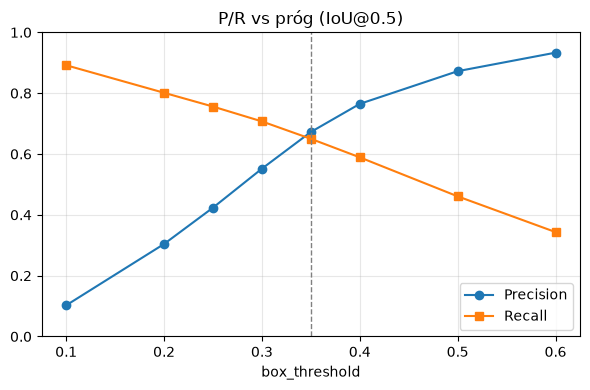

,box_threshold,iou_match,TP,FP (nadmiarowe),FN (brakujące),precision,recall,mean_IoU_of_TP
0,0.10,0.5,32403,283572,3932,0.103,0.892,0.846
1,0.20,0.5,29113,66616,7222,0.304,0.801,0.855
2,0.25,0.5,27467,37381,8868,0.424,0.756,0.860
3,0.30,0.5,25693,20873,10642,0.552,0.707,0.865
4,0.35,0.5,23614,11506,12721,0.672,0.650,0.871
5,0.40,0.5,21401,6580,14934,0.765,0.589,0.878
6,0.50,0.5,16742,2451,19593,0.872,0.461,0.892
7,0.60,0.5,12474,893,23861,0.933,0.343,0.904


In [14]:
sweep = pd.DataFrame([threshold_metrics(predictions, t, IOU_MATCH)[0] for t in [0.1, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6]])
sweep.to_csv(RUN_DIR / "threshold_sweep.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sweep.box_threshold, sweep.precision, "o-", label="Precision")
ax.plot(sweep.box_threshold, sweep.recall, "s-", label="Recall")
ax.axvline(BOX_THRESHOLD, color="gray", ls="--", lw=1)
ax.set_xlabel("box_threshold"); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"P/R vs próg (IoU@{IOU_MATCH})")
fig.tight_layout(); fig.savefig(FIG_DIR / "threshold_sweep.png", dpi=150); plt.show()
sweep.round(3)

## 9. Przykłady jakościowe (zielone = GT, czerwone = predykcje ≥ `box_threshold`)

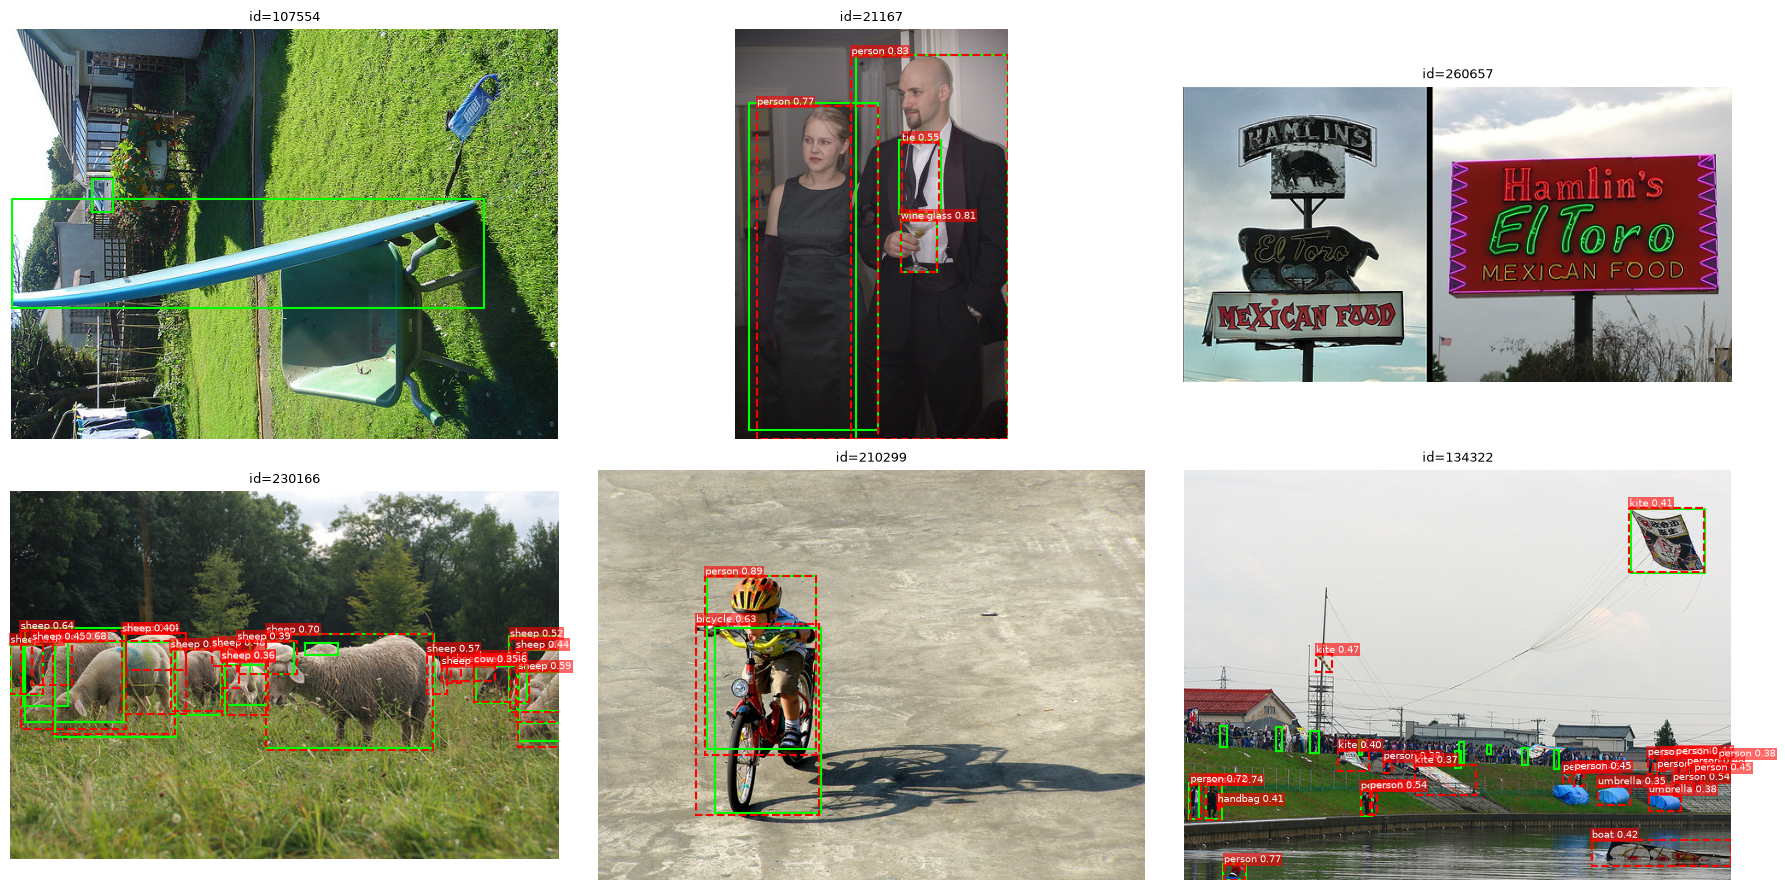

In [15]:
def show_examples(n=6, seed=SEED):
    by_img = defaultdict(list)
    for d in predictions:
        if d["score"] >= BOX_THRESHOLD:
            by_img[d["image_id"]].append(d)
    ids = random.Random(seed).sample(img_ids, n)
    cols = 3
    fig, axes = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(6 * cols, 4.5 * np.ceil(n / cols)))
    for ax, img_id in zip(axes.flat, ids):
        info = coco_gt.imgs[img_id]
        ax.imshow(Image.open(IMG_DIR / info["file_name"]).convert("RGB")); ax.axis("off")
        for a in coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id, iscrowd=False)):
            x, y, w, h = a["bbox"]
            ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="lime", lw=1.5))
        for d in by_img[img_id]:
            x, y, w, h = d["bbox"]
            ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="red", lw=1.5, ls="--"))
            ax.text(x, y - 2, f"{coco_gt.cats[d['category_id']]['name']} {d['score']:.2f}",
                    color="white", fontsize=7, bbox=dict(fc="red", alpha=0.6, pad=1, lw=0))
        ax.set_title(f"id={img_id}", fontsize=9)
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    fig.tight_layout(); fig.savefig(FIG_DIR / "examples.png", dpi=120); plt.show()

show_examples()

## 10. Podsumowanie

In [16]:
print(f"Run: {RUN_DIR.relative_to(ROOT)}   (obrazów: {len(img_ids)})")
print(f"AP  ours = {coco_metrics['AP']:.1f}   paper = {PAPER_RESULTS['AP']}   diff = {coco_metrics['AP'] - PAPER_RESULTS['AP']:+.1f}")
print(f"AP50 = {coco_metrics['AP50']:.1f}, AP75 = {coco_metrics['AP75']:.1f}")
print(f"@box_threshold={BOX_THRESHOLD}: P = {thr_summary['precision']:.3f}, R = {thr_summary['recall']:.3f}, "
      f"FP = {thr_summary['FP (nadmiarowe)']}, FN = {thr_summary['FN (brakujące)']}")
print("\nPliki:")
for p in sorted(RUN_DIR.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(RUN_DIR)}  ({p.stat().st_size / 1024:.0f} KB)")

Run: results/exp01_coco_zeroshot_val2017/swint_ogc_hf__nall_seed42   (obrazów: 5000)
AP  ours = 48.6   paper = 48.4   diff = +0.2
AP50 = 64.5, AP75 = 53.1
@box_threshold=0.35: P = 0.672, R = 0.650, FP = 11506, FN = 12721

Pliki:
  comparison_with_paper.csv  (0 KB)
  config.json  (1 KB)
  env.json  (0 KB)
  figures/ap_per_class.png  (194 KB)
  figures/examples.png  (3341 KB)
  figures/pr_curve.png  (70 KB)
  figures/threshold_sweep.png  (50 KB)
  metrics_coco.json  (0 KB)
  metrics_per_class.csv  (2 KB)
  metrics_thresholded.json  (0 KB)
  metrics_thresholded_per_class.csv  (3 KB)
  predictions.json  (143051 KB)
  threshold_sweep.csv  (1 KB)
